# KDD Project: Customer Segments, Cross-Sell Rules and Repurchase Prediction for a UK Online Gift Retailer

**Methodology:** KDD — *Knowledge Discovery in Databases* (Fayyad, Piatetsky-Shapiro & Smyth, 1996): Selection → Preprocessing → Transformation → Data Mining → Interpretation/Evaluation → using the discovered knowledge.
**Dataset:** *Online Retail* (UCI / Kaggle `carrie1/ecommerce-data`): 541,909 invoice lines, 1 Dec 2010 – 9 Dec 2011, a UK-based online retailer of giftware that sells to consumers and wholesalers.
**Course:** SJSU Data Mining — assignment with three methodologies and one dataset each (CRISP-DM: Telco churn · SEMMA: student performance · **KDD: this notebook**).

Run in Google Colab: *Runtime → Run all* (about 2–4 minutes). If `data/data.csv` is missing the notebook downloads the UCI xlsx (tested, same 541,909 rows). If that is blocked, upload `data.csv` from Kaggle `carrie1/ecommerce-data` to `data/`.

| KDD step (Fayyad et al.) | Where in this notebook |
|---|---|
| Pre-KDD: domain, prior knowledge, goals | Section 0 |
| 1 Selection (target data) | Section 1 |
| 2 Preprocessing & cleaning | Section 2 |
| 3 Transformation | Section 3 |
| 4 Data Mining (choose task → algorithm → run) | Section 4 (a segmentation, b association rules, c prediction) |
| 5 Interpretation / Evaluation | Section 5 |
| Using & consolidating discovered knowledge | Section 6 |

> **Integrity note.** All interpretation text was written *after* executing the notebook and reading the outputs. Where results are weak, tied or fragile that is stated. Critic-loop reviews are logged separately in `critic_log/`.

In [1]:
import os, sys, json, zipfile, warnings, subprocess, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
try:
    import mlxtend, openpyxl
except ImportError:                                   # Colab: install the two extras quietly
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlxtend", "openpyxl"], check=True)
SEED = 42
rng_global = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
for d in ["data", "artifacts", "src", "deploy"]: os.makedirs(d, exist_ok=True)

CSV = "data/data.csv"; XLSX = "data/Online Retail.xlsx"
UCI = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
def load_raw():
    if os.path.exists(CSV):
        return pd.read_csv(CSV, encoding="latin1")
    if not os.path.exists(XLSX):
        print("Downloading UCI Online Retail ...")
        urllib.request.urlretrieve(UCI, "data/online_retail.zip"); zipfile.ZipFile("data/online_retail.zip").extractall("data")
    return pd.read_excel(XLSX)
raw = load_raw()
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str); raw["StockCode"] = raw["StockCode"].astype(str)
if not pd.api.types.is_datetime64_any_dtype(raw["InvoiceDate"]):
    raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
print(raw.shape, "|", raw.InvoiceDate.min(), "->", raw.InvoiceDate.max())

(541909, 8) | 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


---
# Section 0 — Pre-KDD: understanding the domain, prior knowledge and goals

## 0.1 Application domain
A UK-registered online shop selling all-occasion giftware (mugs, candle holders, paper craft, kitchenware). Many customers are **wholesalers**, so a few buyers place very large, regular orders, while the bulk are occasional consumers. Orders are placed per *invoice* (one basket); a cancellation/return has its own invoice number prefixed `C`. Revenue is strongly seasonal (autumn stock-up for Christmas).

## 0.2 Relevant prior knowledge
- **Customer value is skewed** (Pareto): a minority of customers produce most revenue → RFM (Recency, Frequency, Monetary; Hughes 1994) is the classic compact representation and needs log-transforms.
- **Market-basket mining** (Agrawal & Srikant 1994; FP-Growth, Han et al. 2000): raw rules are dominated by *product variants* (same item in different colours) — they are statistically strong but commercially trivial and must be filtered.
- **Temporal leakage** is the main risk when predicting future purchasing from history: features must be computed strictly before the prediction date, and the evaluation period must come after training.
- Data quirks documented by the data owners: cancellation invoices, non-product stock codes (postage, manual adjustments, bank charges), ~25% of lines without `CustomerID`.

## 0.3 Goals of the KDD process (end-user view)
The (hypothetical) marketing manager wants knowledge she can *act on* in the autumn campaign, not just models.

| # | Goal | Pattern type | Measurable success test |
|---|---|---|---|
| G1 | **Understand the customer base** as a handful of actionable groups | Clusters (segmentation) | 3–6 segments; stable under resampling (bootstrap ARI ≥ 0.75, no segment < 3% of customers); segments differ in *future* behaviour measured out-of-time |
| G2 | **Find cross-sell associations** for "customers also bought" widgets and bundles | Association rules | Rules with lift ≥ 1.5 and confidence ≥ 0.5 that are *non-trivial* (not colour variants, not redundant) and still hold (lift > 1) in a later period |
| G3 | **Predict which customers will purchase in the next 90 days** (to time re-engagement) | Supervised classification | Beats the simple *recency-only* rule on a **later** cutoff; paired bootstrap CI for AUC difference reported (if it includes 0 we call it a tie) |

*Out of scope:* causal uplift of campaigns (no campaign data), product demand forecasting, non-UK markets.

---
# Section 1 — Selection: creating the target data set
**Questions:** which records, which period, which variables are relevant to G1–G3?

,lines,amount,line_share
Country,,,
United Kingdom,495478,8187806.364,0.914
Germany,9495,221698.210,0.018
France,8557,197403.900,0.016
EIRE,8196,263276.820,0.015
Spain,2533,54774.580,0.005
Netherlands,2371,284661.540,0.004


Distinct countries: 38 | lines with CustomerID: 75.1%


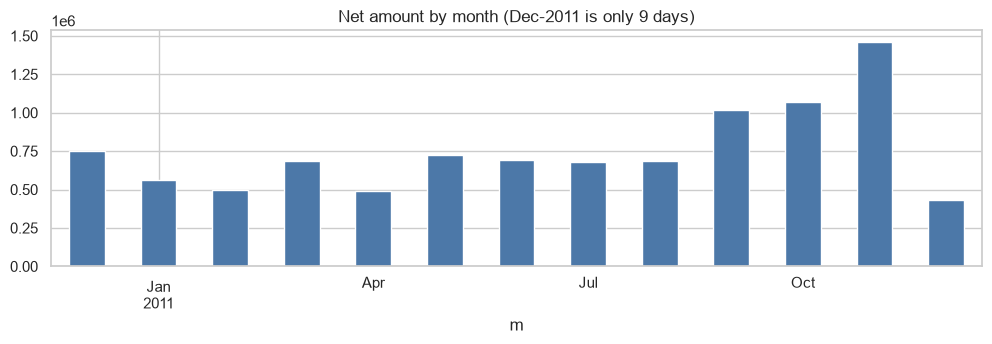

In [2]:
amt = (raw.Quantity * raw.UnitPrice)
by_country = raw.assign(amt=amt).groupby("Country").agg(lines=("amt", "size"), amount=("amt", "sum")).sort_values("lines", ascending=False)
by_country["line_share"] = by_country.lines / by_country.lines.sum()
display(by_country.head(6).round(3))
print("Distinct countries:", raw.Country.nunique(), "| lines with CustomerID:", f"{raw.CustomerID.notna().mean():.1%}")

monthly = raw.assign(m=raw.InvoiceDate.dt.to_period("M"), amt=amt).groupby("m").agg(amount=("amt", "sum"), invoices=("InvoiceNo", "nunique"))
fig, ax = plt.subplots(figsize=(10, 3.6)); monthly.amount.plot.bar(ax=ax, color="#4C78A8"); ax.set_title("Net amount by month (Dec-2011 is only 9 days)"); plt.tight_layout()
plt.savefig("artifacts/monthly_amount.png", dpi=120); plt.show()

### Selection decisions
| Decision | Choice | Justification |
|---|---|---|
| Geography | **United Kingdom only** | ~91% of lines; one shipping/price regime. Each other country contributes < 2% of lines (38 countries); pooling them would mix different shipping regimes and customer types into the UK segments. |
| Period | Full range, but **analysis cut-offs** are fixed later (Section 3/4): features before *1 Sep 2011*, outcomes 1 Sep – 30 Nov 2011 | Last month is partial (9 days of Dec) so Dec-2011 is never used as an outcome window. |
| Records for customer tasks (G1, G3) | Only lines with a `CustomerID` | RFM needs a customer key. |
| Records for basket mining (G2) | **All** UK invoices, including anonymous ones | A basket does not need to know *who* bought it, so dropping 25% of lines would waste data. |
| Variables | `InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID` (+`Country` for selection) | All 8 columns are relevant; `Revenue = Quantity × UnitPrice` is derived. |

In [3]:
flow = []
def snap(step, df, note=""):
    flow.append(dict(step=step, rows=len(df), invoices=df.InvoiceNo.nunique(), customers=int(df.CustomerID.nunique()), note=note))
snap("0  raw file", raw, "starting point")
uk = raw[raw.Country == "United Kingdom"].copy()
snap("1  Selection: UK only", uk, "justified above")

---
# Section 2 — Preprocessing and cleaning
For each problem: **detect → inspect → decide → record row counts** (data-flow table at the end of this section).

In [4]:
# 2.1 Exact duplicates (same invoice, product, qty, time, price, customer)
dups = uk.duplicated().sum(); print("exact duplicate lines:", dups)
display(uk[uk.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(6))
d = uk.drop_duplicates()
snap("2  drop exact duplicate lines", d, "assumed double-scan artefacts; ~1% of lines (a customer buying 2 identical lines in one second is implausible)")

# 2.2 Cancellations / returns ('C' invoices) are set aside, not deleted: used later for the return-ratio feature
is_cancel = d.InvoiceNo.str.startswith("C")
returns_raw = d[is_cancel].copy(); d = d[~is_cancel]
snap("3  set aside cancellation invoices (C...)", d, f"{len(returns_raw):,} lines moved to returns table")

# 2.3 Non-cancel lines with Quantity <= 0 (stock adjustments, damaged goods)
bad_q = d[d.Quantity <= 0]; print("non-cancel Quantity<=0 lines:", len(bad_q), "| of which missing CustomerID:", bad_q.CustomerID.isna().mean().round(3),
      "| Description missing:", bad_q.Description.isna().mean().round(3))
display(bad_q.Description.value_counts().head(5))
d = d[d.Quantity > 0]
snap("4  drop Quantity <= 0", d, "internal stock adjustments, not customer purchases")

# 2.4 UnitPrice <= 0 (free samples, adjustments)
print("UnitPrice<=0 lines:", (d.UnitPrice <= 0).sum(), "| missing CustomerID:", d[d.UnitPrice <= 0].CustomerID.isna().mean().round(3))
d = d[d.UnitPrice > 0]
snap("5  drop UnitPrice <= 0", d, "no commercial value / adjustments")

# 2.5 Non-product stock codes (postage, manual, bank charges, Amazon fee, gift vouchers, ...)
PRODUCT = r"^\d{5}[A-Za-z]{0,2}$"
nonprod = d[~d.StockCode.str.match(PRODUCT)]
print("non-product lines:", len(nonprod)); display(nonprod.StockCode.value_counts().head(10).to_frame("lines"))
d = d[d.StockCode.str.match(PRODUCT)]
snap("6  drop non-product stock codes", d, "POST, DOT, M, D, S, C2, BANK CHARGES, AMAZONFEE, CRUK, gift_*, DCGS*...")

# 2.6 Noise: extreme quantities
print("max quantity per line:", d.Quantity.max()); display(d[d.Quantity >= 10000][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]])
d = d[d.Quantity < 10000]
snap("7  drop line quantity >= 10,000", d, "two mega-orders (74,215 and 80,995 units; each was cancelled within minutes by a `C` invoice); other bulk lines are genuine wholesale and kept")

exact duplicate lines: 5178


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom


non-cancel Quantity<=0 lines: 1336 | of which missing CustomerID: 1.0 | Description missing: 0.645


Description
check                    120
damages                   45
damaged                   42
?                         41
sold as set on dotcom     20
Name: count, dtype: int64

UnitPrice<=0 lines: 1158 | missing CustomerID: 0.979
non-product lines: 1147


,lines
StockCode,
DOT,706
M,274
POST,52
C2,30
DCGSSGIRL,13
BANK CHARGES,12
DCGSSBOY,11
gift_0001_20,9
gift_0001_10,8


max quantity per line: 80995


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00


In [5]:
# 2.7 Missing values: Description / CustomerID.  Treatment depends on the task (see Section 1).
d = d.copy(); d["Revenue"] = d.Quantity * d.UnitPrice
print("missing Description:", d.Description.isna().sum(), "| missing CustomerID:", d.CustomerID.isna().sum(), f"({d.CustomerID.isna().mean():.1%})")
sales = d                                             # all clean UK product lines  -> basket mining (G2)
cs = sales.dropna(subset=["CustomerID"]).copy(); cs["CustomerID"] = cs.CustomerID.astype(int)   # -> customer tasks (G1, G3)
snap("8  customer-level table (drop missing CustomerID)", cs, "anonymous lines kept in `sales` for basket mining")

# returns table (customers known, valid product, positive price)
ret = returns_raw[returns_raw.CustomerID.notna() & returns_raw.StockCode.str.match(PRODUCT) & (returns_raw.UnitPrice > 0)].copy()
ret["CustomerID"] = ret.CustomerID.astype(int); ret["ReturnValue"] = -ret.Quantity * ret.UnitPrice
print("usable return lines:", len(ret), "| total return value:", round(ret.ReturnValue.sum()), "vs sales", round(cs.Revenue.sum()))

# 2.8 Sanity: dates, invoice integrity
print("invoices with >1 distinct timestamp:", int((cs.groupby("InvoiceNo").InvoiceDate.nunique() > 1).sum()), "| invoices spanning >1 customer:", int((cs.groupby("InvoiceNo").CustomerID.nunique() > 1).sum()))
flow_df = pd.DataFrame(flow); flow_df["rows_removed"] = (flow_df.rows.shift(1) - flow_df.rows).fillna(0).astype(int)
flow_df

missing Description: 0 | missing CustomerID: 129966 (27.1%)
usable return lines: 7218 | total return value: 440310 vs sales 6997202
invoices with >1 distinct timestamp: 27 | invoices spanning >1 customer: 0


,step,rows,invoices,customers,note,rows_removed
0,0 raw file,541909,25900,4372,starting point,0
1,1 Selection: UK only,495478,23494,3950,justified above,46431
2,2 drop exact duplicate lines,490300,23494,3950,assumed double-scan artefacts; ~1% of lines (a...,5178
3,3 set aside cancellation invoices (C...),482479,20122,3921,"7,821 lines moved to returns table",7821
4,4 drop Quantity <= 0,481143,18786,3921,"internal stock adjustments, not customer purch...",1336
5,5 drop UnitPrice <= 0,479985,18019,3920,no commercial value / adjustments,1158
6,6 drop non-product stock codes,478838,17901,3916,"POST, DOT, M, D, S, C2, BANK CHARGES, AMAZONFE...",1147
7,"7 drop line quantity >= 10,000",478836,17899,3915,"two mega-orders (74,215 and 80,995 units; each...",2
8,8 customer-level table (drop missing CustomerID),348870,16577,3915,anonymous lines kept in `sales` for basket mining,129966


### Data-flow interpretation (numbers from the table above)
- 541,909 raw lines → **478,836** clean UK product lines (88% of raw). **348,870** of them (72.9%) carry a `CustomerID`; the other 129,966 (27.1%) are anonymous and used only for basket mining.
- Biggest single removals: non-UK 46,431; anonymous lines 129,966 (moved, not lost); cancellations 7,821 lines (set aside for the return-ratio feature); exact duplicates 5,178 (1.0% of UK lines).
- **Assumptions I could not verify:** (i) exact duplicates are scanning artefacts — a customer could genuinely buy two identical lines in one second, and I did not test sensitivity to keeping them; (ii) returns cannot be linked to their original invoices, so `return_ratio` is only a rough ratio of return value (≈£0.44M) to sales (≈£7.0M, 6.3%).
- Non-cancel `Quantity<=0` lines were **100% anonymous** and 64.5% had no description (descriptions such as "check", "damages") → internal stock adjustments. `UnitPrice<=0` lines were 97.8% anonymous. So dropping them is low-risk for the customer tasks.
- Both mega-orders (74,215 and 80,995 units) were cancelled within minutes by a `C` invoice; removing them removes only 2 lines. 27 invoices carry more than one timestamp; I use the earliest.
- 3,915 customers have ≥1 valid purchase overall; **2,985** exist at the 1-Sep-2011 snapshot (others first purchase later).

---
# Section 3 — Transformation: finding useful representations
Goals: (i) a **customer × features** table at a *snapshot date* (RFM + extras) with strictly historical features, (ii) approximately symmetric scales for distance-based mining, (iii) a **basket × item** binary matrix for G2, (iv) dimensionality reduction (PCA) to check redundancy.

**Temporal design (prevents leakage).** For a cut-off date *T*: features use invoices **< T**; labels use invoices in **[T, T+90 days)**.
- *Train cut-off* `2011-06-01` → labels June–Aug 2011 (all known before the test cut-off).
- *Test / snapshot cut-off* `2011-09-01` → labels Sep–Nov 2011 (the last full 90 days before the partial December).

In [6]:
def build_features(cs, ret, cutoff, horizon=90):
    cutoff = pd.Timestamp(cutoff); end = cutoff + pd.Timedelta(days=horizon)
    h = cs[cs.InvoiceDate < cutoff]
    inv = h.groupby(["CustomerID", "InvoiceNo"]).agg(date=("InvoiceDate", "min"), rev=("Revenue", "sum"), units=("Quantity", "sum")).reset_index()
    g = inv.groupby("CustomerID")
    f = pd.DataFrame({"recency_days": (cutoff - g.date.max()).dt.days, "frequency": g.size(), "monetary": g.rev.sum(),
                      "tenure_days": (cutoff - g.date.min()).dt.days, "avg_order_value": g.rev.mean(), "units_per_order": g.units.mean()})
    f["n_products"] = h.groupby("CustomerID").StockCode.nunique()
    span = (g.date.max() - g.date.min()).dt.days
    f["avg_gap_days"] = np.where(f.frequency > 1, span / (f.frequency - 1).replace(0, np.nan), np.nan)
    for days in (30, 90):
        r = inv[inv.date >= cutoff - pd.Timedelta(days=days)].groupby("CustomerID")
        f[f"freq_last{days}"] = r.size(); f[f"spend_last{days}"] = r.rev.sum()
    f[["freq_last30", "spend_last30", "freq_last90", "spend_last90"]] = f[["freq_last30", "spend_last30", "freq_last90", "spend_last90"]].fillna(0)
    rh = ret[ret.InvoiceDate < cutoff].groupby("CustomerID").ReturnValue.sum()
    f["return_ratio"] = (rh.reindex(f.index).fillna(0) / f.monetary).clip(0, 1)
    fut = cs[(cs.InvoiceDate >= cutoff) & (cs.InvoiceDate < end)]
    f["buy_next"] = f.index.isin(fut.CustomerID.unique()).astype(int)
    f["spend_next"] = fut.groupby("CustomerID").Revenue.sum().reindex(f.index).fillna(0)
    return f

CUT_TRAIN, CUT_TEST = "2011-06-01", "2011-09-01"
F_tr = build_features(cs, ret, CUT_TRAIN); F_te = build_features(cs, ret, CUT_TEST)
print("train snapshot:", F_tr.shape, "base rate buy_next =", F_tr.buy_next.mean().round(3))
print("test  snapshot:", F_te.shape, "base rate buy_next =", F_te.buy_next.mean().round(3))
F_te.describe().T[["mean", "50%", "max"]].round(2)

train snapshot: (2462, 15) base rate buy_next = 0.491
test  snapshot: (2985, 15) base rate buy_next = 0.56


,mean,50%,max
recency_days,92.54,73.00,273.00
frequency,3.43,2.00,126.00
monetary,1382.67,521.88,130537.23
tenure_days,176.64,184.00,273.00
avg_order_value,342.72,268.67,14844.77
units_per_order,203.56,141.00,6009.33
n_products,48.15,29.00,1137.00
avg_gap_days,58.53,45.67,259.00
freq_last30,0.37,0.00,12.00
spend_last30,159.57,0.00,28610.00


,skew_raw,skew_log1p
recency_days,0.77,-0.90
frequency,8.65,1.37
monetary,15.08,0.35


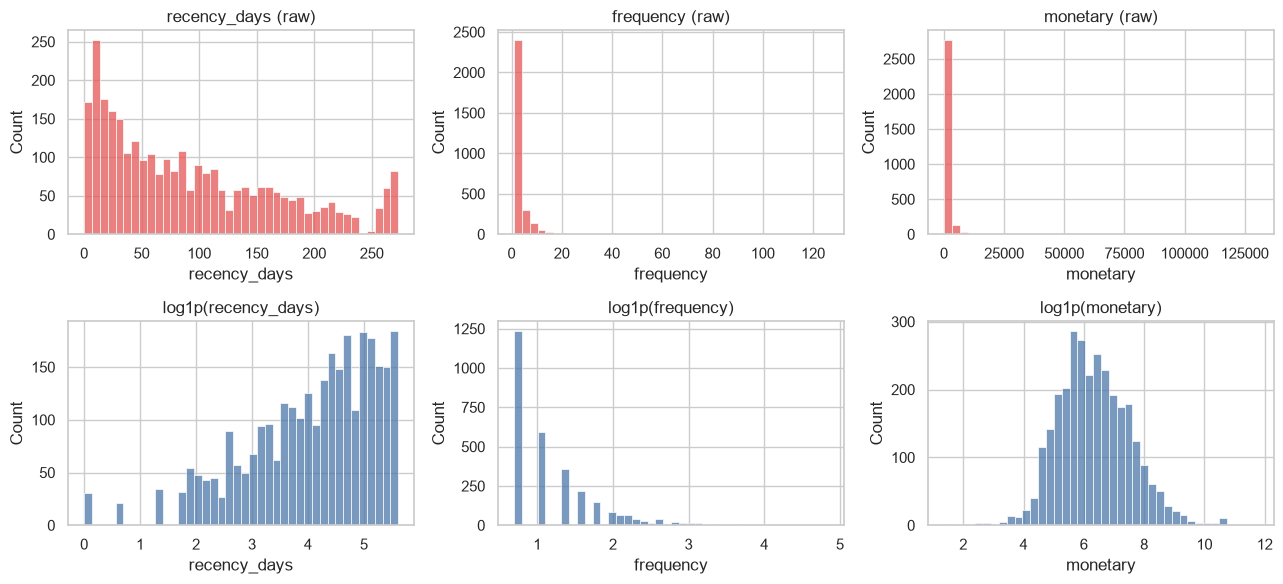

In [7]:
# 3.2 Distribution shape: RFM is heavily right-skewed -> log1p.  (skew = 0 for a symmetric variable)
RFM = ["recency_days", "frequency", "monetary"]
sk = pd.DataFrame({"skew_raw": F_te[RFM].skew(), "skew_log1p": np.log1p(F_te[RFM]).skew()}); display(sk.round(2))
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for j, c in enumerate(RFM):
    sns.histplot(F_te[c], bins=40, ax=ax[0, j], color="#E45756"); ax[0, j].set_title(f"{c} (raw)")
    sns.histplot(np.log1p(F_te[c]), bins=40, ax=ax[1, j], color="#4C78A8"); ax[1, j].set_title(f"log1p({c})")
plt.tight_layout(); plt.savefig("artifacts/rfm_distributions.png", dpi=120); plt.show()

components for 80% / 90% variance: 4 / 5


,PC1,PC2,PC3
recency_days,-0.35,0.29,0.11
frequency,0.34,0.06,0.44
monetary,0.35,0.33,0.07
tenure_days,0.02,0.36,0.64
avg_order_value,0.20,0.47,-0.39
units_per_order,0.20,0.43,-0.43
n_products,0.28,0.27,0.13
freq_last30,0.34,-0.26,-0.00
spend_last30,0.34,-0.24,-0.08
freq_last90,0.37,-0.18,0.10


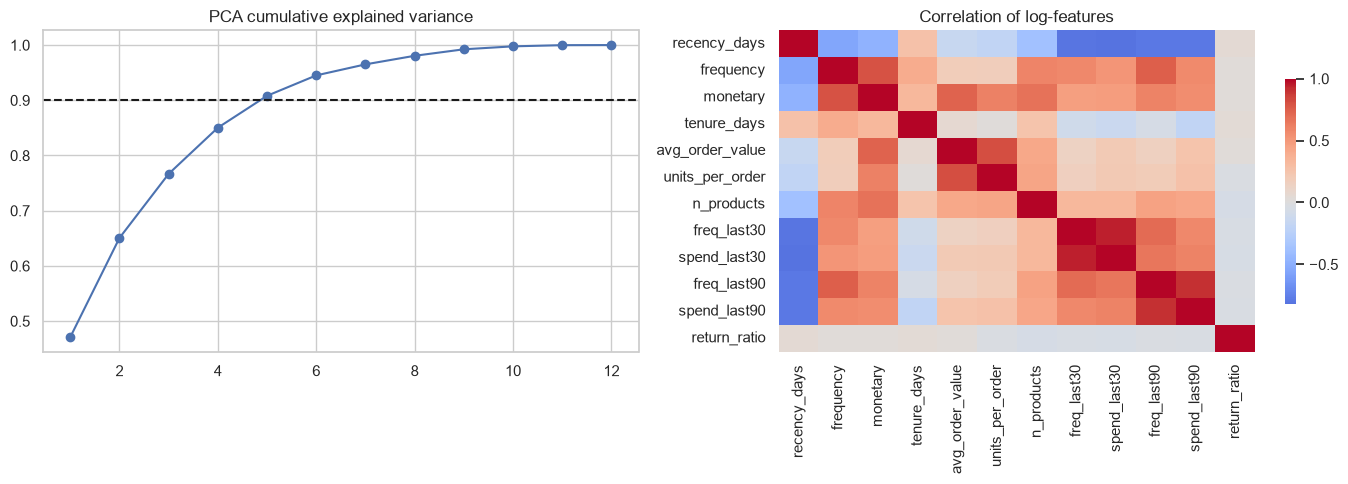

In [8]:
# 3.3 Dimensionality reduction / redundancy among the 12 behavioural features
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
BEH = ["recency_days", "frequency", "monetary", "tenure_days", "avg_order_value", "units_per_order", "n_products", "freq_last30", "spend_last30", "freq_last90", "spend_last90", "return_ratio"]
Z = StandardScaler().fit_transform(np.log1p(F_te[BEH]))
pca = PCA().fit(Z); cum = np.cumsum(pca.explained_variance_ratio_)
print("components for 80% / 90% variance:", int(np.argmax(cum >= .8)) + 1, "/", int(np.argmax(cum >= .9)) + 1)
load = pd.DataFrame(pca.components_[:3].T, index=BEH, columns=["PC1", "PC2", "PC3"]).round(2); display(load)
corr = pd.DataFrame(np.log1p(F_te[BEH])).corr()
fig, ax = plt.subplots(1, 2, figsize=(14, 5)); ax[0].plot(range(1, len(cum) + 1), cum, "o-"); ax[0].axhline(.9, ls="--", c="k"); ax[0].set_title("PCA cumulative explained variance")
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .7}); ax[1].set_title("Correlation of log-features")
plt.tight_layout(); plt.savefig("artifacts/pca_corr.png", dpi=120); plt.show()

### 3.4 Invariance / representation choices
| Issue | Choice |
|---|---|
| Scale-invariance of distances | `log1p` then z-score (fit scaler on snapshot, saved for deployment) |
| Time-invariance of "recency" | Defined *relative to the cut-off date*, not as an absolute date |
| Customer size effects | `avg_order_value`, `units_per_order`, `return_ratio` are ratios, not totals |
| Baskets | Binary presence of product in invoice (quantity ignored: a wholesale order of 144 mugs is still "mug present") |

### What the transformation analysis showed
- Skewness: frequency 8.65 → 1.37 and monetary 15.08 → 0.35 after `log1p`, so the log transform is clearly needed. Recency went from +0.77 to **−0.90** (slightly over-corrected to a left skew); I kept `log1p` for all three for a single consistent, deployable rule.
- PCA on the 12 behavioural features: 4 components give 80% and 5 give 90% of the variance, so the features are substantially redundant. PC1 is an "overall engagement" axis (recency negative; frequency, monetary, last-30/90-day activity all ≈ +0.35); PC2 mixes order size (average order value, units per order) with tenure. `return_ratio` loads ≈ 0 on PC1–PC3, i.e. it carries information not captured by spend/activity.
- Label shift between the two snapshots: **49.1% of customers bought in the training outcome window (Jun–Aug) vs 56.0% in the test window (Sep–Nov)** — consistent with autumn seasonality. Rank metrics (AUC) are insensitive to this but calibrated probabilities would not transfer.

---
# Section 4 — Data mining: choose the task, the algorithm, then search for patterns
| Goal | Task | Algorithm chosen | Why this one | Alternatives compared |
|---|---|---|---|---|
| G1 | Clustering | **K-Means** on log-scaled RFM | Centroids are readable as "typical customer"; fast; deployable by nearest-centroid | Gaussian mixture (BIC), Ward hierarchical, K-Means on PCA scores |
| G2 | Association rules | **FP-Growth** (mlxtend) → rules by lift | Same result as Apriori, faster on 10k+ baskets | (Apriori gives identical itemsets; not re-run) |
| G3 | Classification | **Logistic regression** (interpretable) and **gradient boosting** vs simple rule baselines | Honest comparison to *recency-only* | Frequency-only rule |

## 4a — Customer segmentation (G1)
### Iteration 1 vs 2: does the Section-3 transformation matter?
We evaluate k = 2…8 with silhouette, inertia (elbow) and **bootstrap stability** (re-fit on 20 bootstrap samples, assign *all* customers, adjusted Rand index against the reference clustering) for (1) raw z-scored RFM and (2) log-transformed z-scored RFM.

Iteration 1 — raw z-scored RFM


,inertia,silhouette,ari_mean,ari_min,min_share
k,,,,,
2,6094.261,0.874,0.481,-0.007,0.008
3,3712.087,0.496,0.947,0.799,0.008
4,2800.195,0.521,0.914,0.662,0.008
5,2230.148,0.522,0.849,0.411,0.001
6,1817.801,0.521,0.524,0.404,0.001
7,1426.627,0.444,0.860,0.708,0.001
8,1199.261,0.435,0.700,0.435,0.001


Iteration 2 — log1p + z-scored RFM


,inertia,silhouette,ari_mean,ari_min,min_share
k,,,,,
2,4445.015,0.457,0.963,0.911,0.345
3,3332.340,0.358,0.912,0.816,0.163
4,2670.356,0.368,0.927,0.837,0.137
5,2277.702,0.326,0.858,0.744,0.078
6,2016.506,0.316,0.703,0.423,0.063
7,1810.105,0.277,0.770,0.511,0.052
8,1665.521,0.279,0.709,0.522,0.048


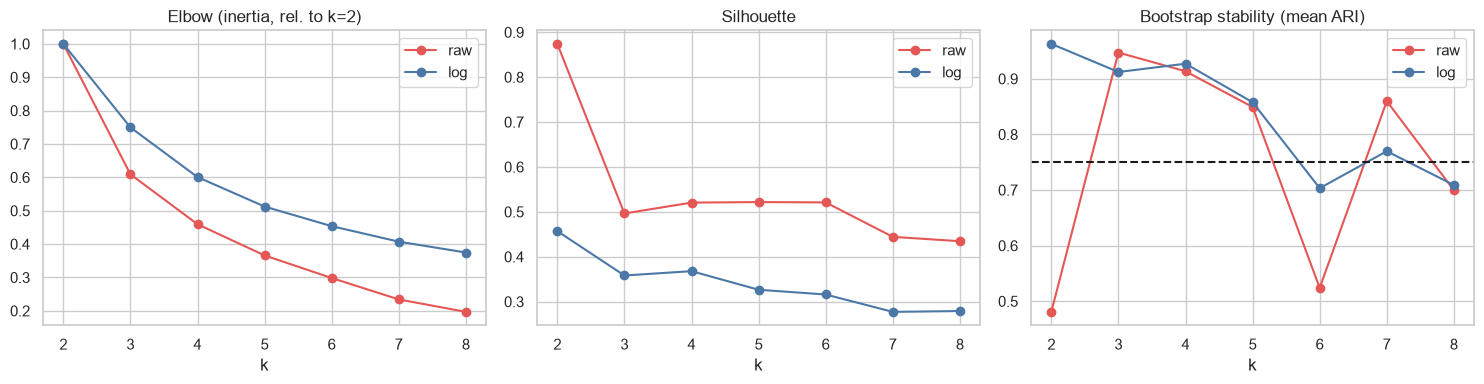

In [9]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

def eval_k(X, ks=range(2, 9), n_boot=20, seed=SEED):
    rg = np.random.default_rng(seed); rows = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=seed).fit(X); lab = km.labels_
        aris = []
        for b in range(n_boot):
            idx = rg.integers(0, len(X), len(X))
            kb = KMeans(k, n_init=5, random_state=b).fit(X[idx]); aris.append(adjusted_rand_score(lab, kb.predict(X)))
        rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X, lab), ari_mean=np.mean(aris), ari_min=np.min(aris),
                         min_share=np.bincount(lab).min() / len(lab)))
    return pd.DataFrame(rows).set_index("k")

X_raw = StandardScaler().fit_transform(F_te[RFM].astype(float))
scaler_log = StandardScaler().fit(np.log1p(F_te[RFM].astype(float))); X_log = scaler_log.transform(np.log1p(F_te[RFM].astype(float)))
ev_raw = eval_k(X_raw); ev_log = eval_k(X_log)
print("Iteration 1 — raw z-scored RFM"); display(ev_raw.round(3))
print("Iteration 2 — log1p + z-scored RFM"); display(ev_log.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for ev, nm, col in [(ev_raw, "raw", "#E45756"), (ev_log, "log", "#4C78A8")]:
    ax[0].plot(ev.index, ev.inertia / ev.inertia.iloc[0], "o-", c=col, label=nm); ax[1].plot(ev.index, ev.silhouette, "o-", c=col, label=nm); ax[2].plot(ev.index, ev.ari_mean, "o-", c=col, label=nm)
for a, t in zip(ax, ["Elbow (inertia, rel. to k=2)", "Silhouette", "Bootstrap stability (mean ARI)"]): a.set_title(t); a.set_xlabel("k"); a.legend()
ax[2].axhline(.75, ls="--", c="k"); plt.tight_layout(); plt.savefig("artifacts/kmeans_selection.png", dpi=120); plt.show()

### Reading the two iterations
- **Raw RFM (iteration 1):** silhouette looks excellent at k = 2 (0.874) but the smallest cluster holds **0.8% of customers** (about 24 people) for every k, and ≤ 0.1% for k ≥ 5. The algorithm is just isolating a handful of very large wholesale buyers; bootstrap ARI at k = 2 is poor (mean 0.48, min −0.01). A high silhouette here is an outlier artefact, not good segmentation.
- **Log RFM (iteration 2):** clusters are balanced (smallest share 34% at k = 2, 16% at k = 3, 14% at k = 4) and stable (mean ARI 0.96, 0.91, 0.93, 0.86, 0.70 for k = 2…6). Silhouette is lower (0.46 at k = 2, 0.36–0.37 at k = 3–4) — **lower silhouette does not mean worse** here, for the reason above. This is the loop back to Step 3 (Transformation).
- The inertia curve declines smoothly (relative drops of about 25%, 20%, 15%, 12%, 10%, 8%): **there is no sharp elbow**, so the elbow gives no vote for a particular k.
- k = 2 has the best silhouette and stability but is excluded by the business requirement (≥ 3 actionable segments, declared in Section 0). That exclusion is a design choice, not a finding of the data.

In [10]:
# Pre-declared selection rule (G1): k in 3..6, mean ARI >= 0.75, smallest segment >= 3%; among eligible take the highest silhouette.
elig = ev_log[(ev_log.index >= 3) & (ev_log.index <= 6) & (ev_log.ari_mean >= .75) & (ev_log.min_share >= .03)]
if len(elig): K = int(elig.silhouette.idxmax()); print("eligible k:", list(elig.index), "-> chosen k =", K)
else:
    K = int(ev_log.loc[3:6].ari_mean.idxmax()); print("NO k met all criteria; falling back to most stable k in 3..6 ->", K)

km = KMeans(K, n_init=20, random_state=SEED).fit(X_log); F_te["cluster"] = km.labels_
# robustness checks: alternative algorithms and a PCA-based representation
gmm_bic = {k: GaussianMixture(k, n_init=5, random_state=SEED).fit(X_log).bic(X_log) for k in range(2, 9)}
gmm = GaussianMixture(K, n_init=10, random_state=SEED).fit(X_log); g_lab = gmm.predict(X_log)
agg_lab = AgglomerativeClustering(K, linkage="ward").fit_predict(X_log)
pcs = PCA(n_components=int(np.argmax(cum >= .9)) + 1).fit_transform(Z); pca_lab = KMeans(K, n_init=20, random_state=SEED).fit_predict(pcs)
agree = pd.Series({"GMM (full cov.)": adjusted_rand_score(km.labels_, g_lab), "Ward hierarchical": adjusted_rand_score(km.labels_, agg_lab),
                   "K-Means on 12-feature PCA (90% var.)": adjusted_rand_score(km.labels_, pca_lab)}, name="ARI vs chosen K-Means")
print("GMM BIC by k:", {k: round(v) for k, v in gmm_bic.items()}, "-> BIC-best k =", min(gmm_bic, key=gmm_bic.get))
display(agree.round(3).to_frame())
print("segment sizes:", np.bincount(km.labels_), "| silhouette:", round(silhouette_score(X_log, km.labels_), 3))

eligible k: [3, 4, 5] -> chosen k = 4


GMM BIC by k: {2: 19505, 3: 6004, 4: -211, 5: -3783, 6: -3921, 7: -5898, 8: -7289} -> BIC-best k = 8


,ARI vs chosen K-Means
GMM (full cov.),0.494
Ward hierarchical,0.673
K-Means on 12-feature PCA (90% var.),0.453


segment sizes: [ 410 1275  848  452] | silhouette: 0.368


In [11]:
# Segment profile + naming helper (name derived from centroid position; checked by reading the profile)
prof = F_te.groupby("cluster").agg(customers=("frequency", "size"), recency_med=("recency_days", "median"), frequency_med=("frequency", "median"),
        monetary_med=("monetary", "median"), aov_med=("avg_order_value", "median"), products_med=("n_products", "median"),
        return_ratio_mean=("return_ratio", "mean"), hist_revenue=("monetary", "sum"),
        future_buy_rate=("buy_next", "mean"), future_spend_mean=("spend_next", "mean"), future_revenue=("spend_next", "sum"))
prof["cust_share"] = prof.customers / prof.customers.sum(); prof["hist_rev_share"] = prof.hist_revenue / prof.hist_revenue.sum(); prof["future_rev_share"] = prof.future_revenue / prof.future_revenue.sum()
cent = pd.DataFrame(scaler_log.inverse_transform(km.cluster_centers_), columns=RFM, index=range(K)).apply(np.expm1)       # centroids in original units
zc = pd.DataFrame(km.cluster_centers_, columns=["zR", "zF", "zM"])                                                    # z-scores of log features
def name_clusters(zc):
    names = {}
    for c, r in zc.iterrows():
        recent, frequent = r.zR < 0, r.zF > 0
        names[c] = ("Loyal active" if recent and frequent else "Recent light buyers" if recent else "At-risk regulars" if frequent else "Lapsed / one-off")
    top = (zc.zF + zc.zM - zc.zR).idxmax(); names[top] = "Champions"
    dup = collections.Counter(names.values())
    seen = collections.Counter(); out = {}
    for c in sorted(names):
        base = names[c]; seen[base] += 1; out[c] = base if dup[base] == 1 else f"{base} ({chr(64 + seen[base])})"
    return out
import collections
NAMES = name_clusters(zc); prof.insert(0, "segment", prof.index.map(NAMES)); cent.insert(0, "segment", cent.index.map(NAMES))
display(prof.round(3)); print("centroids (original units):"); display(cent.round(1))

,segment,customers,recency_med,frequency_med,monetary_med,aov_med,products_med,return_ratio_mean,hist_revenue,future_buy_rate,future_spend_mean,future_revenue,cust_share,hist_rev_share,future_rev_share
cluster,,,,,,,,,,,,,,,
0,Recent light buyers,410,13.0,2.0,535.280,259.285,30.0,0.011,274391.99,0.568,470.859,193052.05,0.137,0.066,0.094
1,Lapsed / one-off,1275,147.0,1.0,229.330,193.000,15.0,0.021,334804.42,0.373,190.230,242543.26,0.427,0.081,0.118
2,At-risk regulars,848,73.0,3.0,910.045,317.682,48.0,0.030,988763.15,0.643,492.246,417425.03,0.284,0.240,0.203
3,Champions,452,14.0,8.0,2924.280,354.638,92.0,0.018,2529300.07,0.925,2667.008,1205487.72,0.151,0.613,0.586


centroids (original units):


,segment,recency_days,frequency,monetary
0,Recent light buyers,11.5,2.1,515.7
1,Lapsed / one-off,130.8,1.1,215.0
2,At-risk regulars,71.3,3.0,958.7
3,Champions,13.3,9.4,3482.7


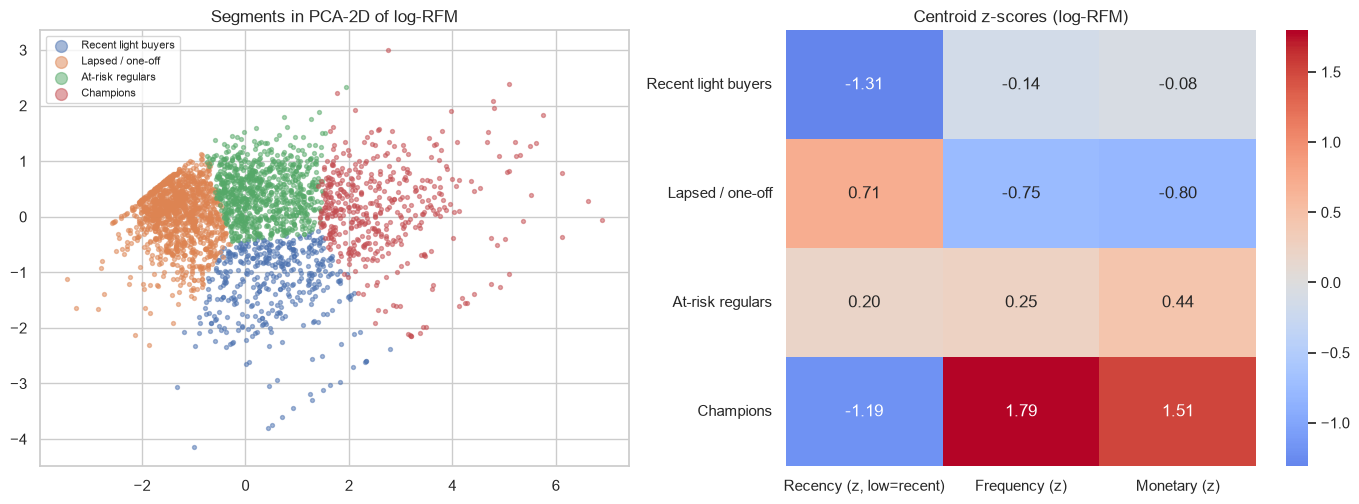

In [12]:
# Visual: segments in PCA-2D of the RFM space + RFM profile heatmap
P2 = PCA(2).fit_transform(X_log)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for c in range(K): ax[0].scatter(P2[km.labels_ == c, 0], P2[km.labels_ == c, 1], s=8, alpha=.5, label=NAMES[c])
ax[0].set_title("Segments in PCA-2D of log-RFM"); ax[0].legend(markerscale=3, fontsize=8)
hm = zc.copy(); hm.index = [NAMES[i] for i in hm.index]; hm.columns = ["Recency (z, low=recent)", "Frequency (z)", "Monetary (z)"]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Centroid z-scores (log-RFM)")
plt.tight_layout(); plt.savefig("artifacts/segments.png", dpi=120); plt.show()

### Interpretation of the four segments (all numbers from the profile table; outcome window = Sep–Nov 2011)
| Segment | Customers | Typical customer | Share of history revenue | Future purchase rate | Share of future revenue |
|---|---|---|---|---|---|
| Champions | 452 (15.1%) | median 8 orders, 92 products, last bought 14 days before snapshot, £2.9k | 61.3% | 92.5% | 58.6% |
| At-risk regulars | 848 (28.4%) | 3 orders, last bought 73 days ago, £0.9k | 24.0% | 64.3% | 20.3% |
| Recent light buyers | 410 (13.7%) | 2 orders, last bought 13 days ago, £0.5k | 6.6% | 56.8% | 9.4% |
| Lapsed / one-off | 1,275 (42.7%) | 1 order, last bought 147 days ago, £0.2k | 8.1% | 37.3% | 11.8% |

**What this supports:** a small group (15% of customers) produces ~60% of revenue both before and after the snapshot, and the segments differ strongly in what happens next (37%–93% purchase rate). The segmentation is stable under resampling (bootstrap ARI 0.927).

**What it does not support — read before using the playbook:**
1. **The clusters are a partition of a continuum, not natural groups.** Silhouette is 0.368 (weak–moderate), and a Gaussian mixture's BIC keeps improving up to k = 8 (no natural k). Agreement of the chosen K-Means with other methods is only partial: Ward ARI 0.67, GMM 0.49, K-Means on the 12-feature PCA 0.45. Bootstrap ARI measures stability of K-Means to sampling, not agreement across methods.
2. The future-rate spread is **partly circular**: recency and frequency define the segments *and* predict repurchase. It shows the segments are useful, not that they are independent discoveries.
3. **Names come from a heuristic on centroid z-scores**, not from evidence. "At-risk regulars" actually buy again at 64% — above the 56% population rate — so "at-risk" is a label for *longer since last purchase, above-average frequency*, not proof of imminent churn. "Recent light buyers" (56.8%) are barely above the population rate, so recency alone does not make them likely repeaters; the "second-purchase nudge" is an untested hypothesis. Lapsed customers still generate 11.8% of future revenue, so "low-cost reactivation" should not be read as "ignore".
4. No campaign data exists, so every action in the playbook is a hypothesis to A/B test.

## 4b — Association rules for cross-selling (G2)
**Design.** Baskets = UK invoices (anonymous included). *Mining period*: invoices before 1 Sep 2011; *validation period*: 1 Sep – 9 Dec 2011. To keep the matrix tractable we use the **200 most frequent products** in the mining period and baskets that contain **at least 2 of them** (the same filter in both periods, so supports are conditional on that filter — a documented simplification). FP-Growth, `min_support = 0.02`, itemsets up to length 3; rules by lift.

In [13]:
from mlxtend.frequent_patterns import fpgrowth, association_rules
SPLIT = pd.Timestamp("2011-09-01"); TOP_N = 200
desc_map = sales.groupby("StockCode").Description.agg(lambda s: s.mode().iat[0] if s.notna().any() else "").str.strip()
inv_items = sales[["InvoiceNo", "StockCode"]].drop_duplicates()
inv_date = sales.groupby("InvoiceNo").InvoiceDate.min()
mine_inv = inv_date.index[inv_date < SPLIT]; val_inv = inv_date.index[inv_date >= SPLIT]
top_items = inv_items[inv_items.InvoiceNo.isin(mine_inv)].StockCode.value_counts().head(TOP_N).index
def basket(invs):
    x = inv_items[inv_items.InvoiceNo.isin(invs) & inv_items.StockCode.isin(top_items)]
    b = pd.crosstab(x.InvoiceNo, x.StockCode).astype(bool).reindex(columns=top_items, fill_value=False)
    return b[b.sum(axis=1) >= 2]
B_mine, B_val = basket(mine_inv), basket(val_inv)
print("baskets (>=2 top items): mining", B_mine.shape, "| validation", B_val.shape, "| avg items/basket (mining):", B_mine.sum(axis=1).mean().round(2))
freq = fpgrowth(B_mine, min_support=0.02, use_colnames=True, max_len=3)
print("frequent itemsets:", len(freq), "| by length:", freq.itemsets.map(len).value_counts().sort_index().to_dict())
rules = association_rules(freq, num_itemsets=len(B_mine), metric="lift", min_threshold=1.0)
rules = rules[(rules.confidence >= .5) & (rules.lift >= 1.5)].copy()
print("rules with confidence>=0.5 & lift>=1.5:", len(rules))

baskets (>=2 top items): mining (8608, 200) | validation (4654, 200) | avg items/basket (mining): 10.34


frequent itemsets: 526 | by length: {1: 200, 2: 265, 3: 61}
rules with confidence>=0.5 & lift>=1.5: 253


In [14]:
# Filter 1: trivial 'variant' rules (same product family, different colour/size). Token similarity after removing colour & filler words.
COLOURS = set("PINK RED GREEN BLUE YELLOW PURPLE ORANGE WHITE BLACK IVORY CREAM SILVER GOLD TURQUOISE LILAC BROWN GREY CLEAR".split())
STOP = set("OF AND SET THE A IN WITH FOR".split())
def toks(code): return {t for t in desc_map.get(code, "").upper().replace("-", " ").split() if t not in COLOURS and t not in STOP}
def jacc(a, b): return len(a & b) / max(1, len(a | b))
def is_variant(a, c, thr=.5): return any(jacc(toks(x), toks(y)) >= thr for x in a for y in c)
rules["variant"] = [is_variant(a, c) for a, c in zip(rules.antecedents, rules.consequents)]
# Filter 2: redundancy — drop a rule if a simpler rule (antecedent strict subset, same consequent) has confidence >= this rule's - 0.02
def redundant(r, pool):
    for _, s in pool[pool.consequents == r.consequents].iterrows():
        if s.antecedents < r.antecedents and s.confidence >= r.confidence - .02: return True
    return False
nv = rules[~rules.variant]; rules["redundant"] = False
rules.loc[nv.index, "redundant"] = [redundant(r, nv) for _, r in nv.iterrows()]
print(f"rules: {len(rules)} | colour/size variants: {int(rules.variant.sum())} | redundant (non-variant): {int(rules.redundant.sum())} | kept: {int((~rules.variant & ~rules.redundant).sum())}")
keep = rules[~rules.variant & ~rules.redundant].copy()

rules: 253 | colour/size variants: 159 | redundant (non-variant): 0 | kept: 94


In [15]:
# Out-of-time validation: recompute support/confidence/lift of each retained (and variant) rule in the validation baskets
def heldout(R, B):
    M = B.values; col = {c: i for i, c in enumerate(B.columns)}; out = []
    for a, c in zip(R.antecedents, R.consequents):
        A = M[:, [col[x] for x in a]].all(1); Cc = M[:, [col[x] for x in c]].all(1); AB = A & Cc
        sa, sc, sab = A.mean(), Cc.mean(), AB.mean()
        out.append((sab, sab / sa if sa else np.nan, (sab / sa) / sc if sa and sc else np.nan))
    return pd.DataFrame(out, columns=["val_support", "val_confidence", "val_lift"], index=R.index)
if len(keep):
    keep = keep.join(heldout(keep, B_val))
    print("retained non-trivial rules:", len(keep), "| val lift > 1:", f"{(keep.val_lift > 1).mean():.0%}", "| val lift >= 1.5:", f"{(keep.val_lift >= 1.5).mean():.0%}",
          "| median |conf shift|:", round((keep.val_confidence - keep.confidence).abs().median(), 3), "| corr(lift mine, lift val):", round(keep[["lift", "val_lift"]].corr().iloc[0, 1], 2))
var = rules[rules.variant].copy(); var = var.join(heldout(var, B_val))
print("for comparison, variant (trivial) rules: n =", len(var), "| val lift>1:", f"{(var.val_lift > 1).mean():.0%}", "| median val confidence:", round(var.val_confidence.median(), 2))
def shares_range(a, c): return any(len(toks(x) & toks(y)) >= 2 for x in a for y in c)   # >=2 shared non-colour tokens = same product range
if len(keep):
    keep["same_range"] = [shares_range(a, c) for a, c in zip(keep.antecedents, keep.consequents)]
    print(f"retained rules whose antecedent and consequent share >=2 name tokens (same product range, different design): {keep.same_range.mean():.0%}  ({int(keep.same_range.sum())} of {len(keep)})")
    print("cross-range retained rules:", int((~keep.same_range).sum()), "| their val lift > 1:", f"{(keep[~keep.same_range].val_lift > 1).mean():.0%}" if (~keep.same_range).any() else "n/a")
def label(fs): return " + ".join(desc_map.get(x, x).title() for x in sorted(fs))
show = keep.sort_values("lift", ascending=False).head(15).copy()
show["antecedent"] = show.antecedents.map(label); show["consequent"] = show.consequents.map(label)
display(show[["antecedent", "consequent", "support", "confidence", "lift", "val_confidence", "val_lift"]].round(3).reset_index(drop=True))

retained non-trivial rules: 94 | val lift > 1: 99% | val lift >= 1.5: 99% | median |conf shift|: 0.046 | corr(lift mine, lift val): 0.75
for comparison, variant (trivial) rules: n = 159 | val lift>1: 100% | median val confidence: 0.62
retained rules whose antecedent and consequent share >=2 name tokens (same product range, different design): 85%  (80 of 94)
cross-range retained rules: 14 | their val lift > 1: 100%


,antecedent,consequent,support,confidence,lift,val_confidence,val_lift
0,Small Marshmallows Pink Bowl,Small Dolly Mix Design Orange Bowl,0.026,0.812,21.580,0.803,21.353
1,Small Dolly Mix Design Orange Bowl,Small Marshmallows Pink Bowl,0.026,0.694,21.580,0.629,21.353
2,Gardeners Kneeling Pad Keep Calm,Gardeners Kneeling Pad Cup Of Tea,0.028,0.645,17.242,0.580,6.417
3,Gardeners Kneeling Pad Cup Of Tea,Gardeners Kneeling Pad Keep Calm,0.028,0.739,17.242,0.720,6.417
4,Jumbo Bag Pears,Jumbo Bag Vintage Leaf,0.020,0.588,12.252,0.500,5.832
5,Woodland Charlotte Bag + Strawberry Charlotte Bag,Charlotte Bag Suki Design,0.021,0.733,11.764,0.832,14.837
6,Woodland Charlotte Bag + Red Retrospot Charlot...,Charlotte Bag Suki Design,0.023,0.716,11.496,0.763,13.608
7,Spaceboy Lunch Box,Dolly Girl Lunch Box,0.032,0.588,10.979,0.652,13.087
8,Dolly Girl Lunch Box,Spaceboy Lunch Box,0.032,0.594,10.979,0.655,13.087
9,Strawberry Charlotte Bag + Red Retrospot Charl...,Charlotte Bag Suki Design,0.024,0.680,10.918,0.748,13.345


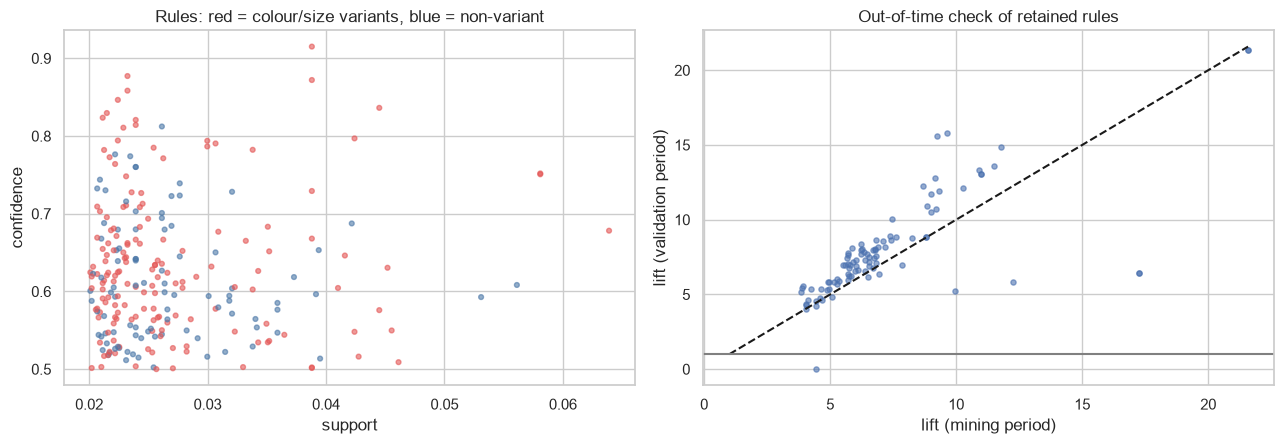

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(rules.support, rules.confidence, c=np.where(rules.variant, "#E45756", "#4C78A8"), s=12, alpha=.6); ax[0].set_xlabel("support"); ax[0].set_ylabel("confidence"); ax[0].set_title("Rules: red = colour/size variants, blue = non-variant")
if len(keep): ax[1].scatter(keep.lift, keep.val_lift, s=14, alpha=.6); ax[1].plot([1, keep.lift.max()], [1, keep.lift.max()], "k--"); ax[1].axhline(1, c="gray"); ax[1].set_xlabel("lift (mining period)"); ax[1].set_ylabel("lift (validation period)"); ax[1].set_title("Out-of-time check of retained rules")
plt.tight_layout(); plt.savefig("artifacts/rules.png", dpi=120); plt.show()

### Interpretation of the rules
- 526 frequent itemsets (200 singletons, 265 pairs, 61 triples) → 253 rules with confidence ≥ 0.5 and lift ≥ 1.5. **159 (63%) were colour/size variants** and were set aside; the redundancy filter removed **0** further rules (it was inert in this data), leaving **94**.
- **Out-of-time:** 99% of retained rules have lift > 1 in Sep–Dec (99% ≥ 1.5), median confidence shift 0.046, correlation of mining-period vs validation-period lift 0.75. The *variant* rules were equally stable (100% lift > 1), so out-of-time stability **does not distinguish interesting rules from trivial ones**; it shows that product-range co-purchase is a persistent structure. Individual lifts do move (e.g. the Gardeners Kneeling Pad pair falls from 17.2 to 6.4; the Charlotte Bag/Suki rules rise to 12–15).
- **Honest weakness of the filter:** the token-overlap variant filter catches colour variants but **not different designs of the same range**. By a stricter test (≥ 2 shared non-colour name tokens) **85% (80/94) of the retained rules are still same-range rules** (e.g. Dolly Girl Lunch Box ↔ Spaceboy Lunch Box, the Charlotte Bag family, Jumbo Bag designs). They support "complete the set" bundles but are not surprising. Only **14 rules are cross-range** (all with validation lift > 1); examples in the top-15 table include paper plates → paper napkins and Toy Tidy → Recycling Bag. Those 14 are the genuinely new cross-sell knowledge.
- Caveats: lifts are computed among baskets with ≥ 2 of the 200 most frequent products (avg 10 items/basket → mostly wholesale-style baskets), which inflates lift and may not transfer to small consumer baskets; association ≠ causation; the validation period includes the pre-Christmas peak.

## 4c — Predicting 90-day repurchase (G3), with an out-of-time test
**Design.** Train on the `2011-06-01` snapshot (labels Jun–Aug), test on the `2011-09-01` snapshot (labels Sep–Nov). Models: two rule baselines (*recency only*; *orders in last 90 days*), logistic regression (log-features), and histogram gradient boosting (all 12+ features, NaN-aware). Hyper-parameters are fixed in advance and modest (no tuning on the test period; a stated limitation). Uncertainty: paired bootstrap over test customers.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
FEATS = [c for c in F_tr.columns if c not in ("buy_next", "spend_next", "cluster")]
Xtr, ytr, Xte, yte = F_tr[FEATS], F_tr.buy_next.values, F_te[FEATS], F_te.buy_next.values
lr = Pipeline([("log", FunctionTransformer(np.log1p)), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", LogisticRegression(C=0.5, max_iter=2000))]).fit(Xtr, ytr)
gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=8, min_samples_leaf=30, l2_regularization=1.0, random_state=SEED).fit(Xtr, ytr)
scores = {"Rule: recency only (recent = likely)": -Xte.recency_days.values.astype(float), "Rule: orders in last 90d": Xte.freq_last90.values.astype(float) + 1e-6 * rng_global.random(len(Xte)),
          "Logistic regression": lr.predict_proba(Xte)[:, 1], "Gradient boosting": gb.predict_proba(Xte)[:, 1]}
def lift_at(y, s, q=.2): k = int(q * len(y)); return y[np.argsort(-s)[:k]].mean() / y.mean()
res = pd.DataFrame({n: dict(ROC_AUC=roc_auc_score(yte, s), PR_AUC=average_precision_score(yte, s), Lift_at_20=lift_at(yte, s)) for n, s in scores.items()}).T
print("test base rate:", yte.mean().round(3), "| n test customers:", len(yte)); display(res.round(3))
# paired bootstrap of AUC differences vs the recency-only baseline
rg = np.random.default_rng(SEED); base = scores["Rule: recency only (recent = likely)"]; diffs = {n: [] for n in scores if n != "Rule: recency only (recent = likely)"}
for _ in range(1000):
    i = rg.integers(0, len(yte), len(yte))
    if yte[i].min() == yte[i].max(): continue
    b0 = roc_auc_score(yte[i], base[i])
    for n in diffs: diffs[n].append(roc_auc_score(yte[i], scores[n][i]) - b0)
ci = pd.DataFrame({n: dict(mean_diff=np.mean(v), lo=np.percentile(v, 2.5), hi=np.percentile(v, 97.5)) for n, v in diffs.items()}).T
dg = []
rg2 = np.random.default_rng(SEED + 1)
for _ in range(1000):
    i = rg2.integers(0, len(yte), len(yte))
    if yte[i].min() == yte[i].max(): continue
    dg.append(roc_auc_score(yte[i], scores["Gradient boosting"][i]) - roc_auc_score(yte[i], scores["Logistic regression"][i]))
print(f"GB minus LR AUC: mean {np.mean(dg):+.4f}, 95% CI [{np.percentile(dg, 2.5):+.4f}, {np.percentile(dg, 97.5):+.4f}]")
ci["CI_excludes_0"] = (ci.lo > 0) | (ci.hi < 0); print("AUC difference vs recency-only rule (paired bootstrap, 95% CI):"); display(ci.round(4))

test base rate: 0.56 | n test customers: 2985


,ROC_AUC,PR_AUC,Lift_at_20
Rule: recency only (recent = likely),0.682,0.702,1.358
Rule: orders in last 90d,0.688,0.761,1.513
Logistic regression,0.740,0.805,1.603
Gradient boosting,0.735,0.800,1.594


GB minus LR AUC: mean -0.0057, 95% CI [-0.0160, +0.0052]
AUC difference vs recency-only rule (paired bootstrap, 95% CI):


,mean_diff,lo,hi,CI_excludes_0
Rule: orders in last 90d,0.0068,-0.0057,0.0185,False
Logistic regression,0.0585,0.0421,0.0754,True
Gradient boosting,0.0527,0.0382,0.0677,True


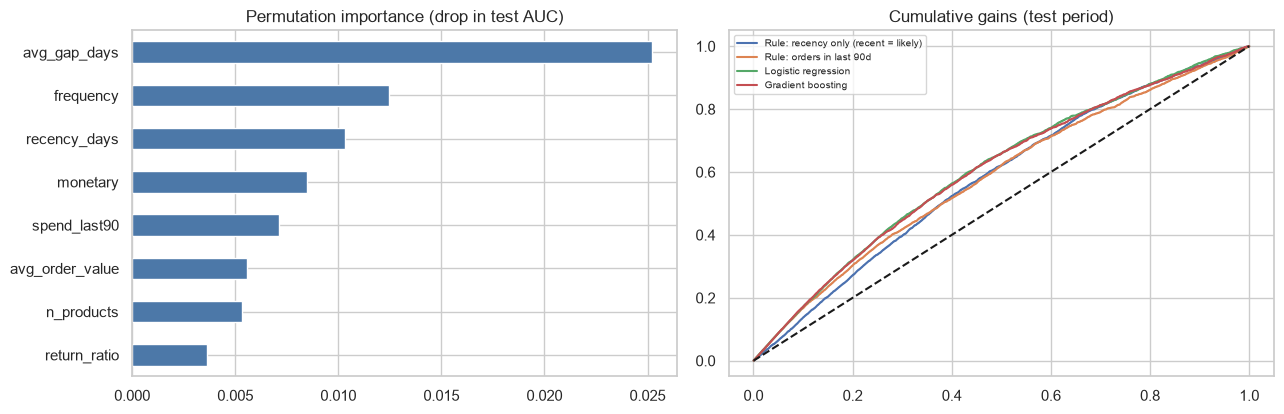

,n,base_rate,AUC_gb,AUC_recency
Recent light buyers,410.0,0.568,0.631,0.530
Lapsed / one-off,1275.0,0.373,0.553,0.547
At-risk regulars,848.0,0.643,0.633,0.603
Champions,452.0,0.925,0.731,0.570


In [18]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(gb, Xte, yte, scoring="roc_auc", n_repeats=8, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3)); imp.head(8).iloc[::-1].plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Permutation importance (drop in test AUC)")
for n, s in scores.items():
    o = np.argsort(-s); ax[1].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(yte[o]) / yte.sum(), label=n)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("Cumulative gains (test period)"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig("artifacts/predict.png", dpi=120); plt.show()
# does the extra modelling help *within* each segment, or is it only segment membership?
seg_auc = F_te.assign(p=scores["Gradient boosting"], r=base).groupby("cluster").apply(lambda g: pd.Series(dict(n=len(g), base_rate=g.buy_next.mean(), AUC_gb=roc_auc_score(g.buy_next, g.p) if g.buy_next.nunique() > 1 else np.nan, AUC_recency=roc_auc_score(g.buy_next, g.r) if g.buy_next.nunique() > 1 else np.nan)))
seg_auc.index = [NAMES[i] for i in seg_auc.index]; display(seg_auc.round(3))

### Interpretation of the repurchase models (test = Sep–Nov 2011 outcomes, 2,985 customers, base rate 56.0%)
| Model | ROC-AUC | PR-AUC | Lift@20% |
|---|---|---|---|
| Recency-only rule | 0.682 | 0.702 | 1.36 |
| Orders-in-last-90-days rule | 0.688 | 0.761 | 1.51 |
| Logistic regression | **0.740** | 0.805 | 1.60 |
| Gradient boosting | 0.735 | 0.800 | 1.59 |

- Both learned models beat the recency-only rule by ≈ 0.05–0.06 AUC and the paired-bootstrap CIs exclude 0 (LR +0.0585 [+0.042, +0.075]; GB +0.0527 [+0.038, +0.068]). The last-90-day rule is **tied** with recency (+0.007, CI includes 0).
- **Logistic regression and gradient boosting are tied** (GB − LR = −0.006, 95% CI [−0.016, +0.005]). The simpler, interpretable model is the sensible choice; extra model complexity bought nothing measurable.
- Absolute performance is **moderate**: AUC ≈ 0.74. Lift@20% = 1.60 looks small but the ceiling at a 56% base rate is 1/0.56 = 1.79, so the top-20% list is about 89% of that ceiling.
- **Within segments the signal is weaker:** gradient-boosting AUC is 0.73 in Champions, 0.63 in At-risk regulars and Recent light buyers, and **0.55 in Lapsed/one-off — barely above chance** (recency-only 0.55). A good part of the overall AUC is *between-segment* separation.
- Caveats: fixed hyper-parameters and one train/test pair of cut-offs (no repeated-cut-off estimate); the same customers appear in both snapshots (realistic for re-scoring the same base, but not a test on new customers); a seasonal base-rate shift (49% → 56%) means probabilities would need recalibration. Feature importance is in the left panel of the figure above.

---
# Section 5 — Interpretation and evaluation of the discovered patterns
Checklist from Fayyad et al.: *interpret → visualise → remove redundant/irrelevant patterns → return to earlier steps if needed → consolidate*. Re-test of G1–G3 against the pre-declared success tests:

In [19]:
checks = []
r = ev_log.loc[K]
checks.append(("G1", f"k = {K} within 3..6", 3 <= K <= 6, f"k={K}"))
checks.append(("G1", "bootstrap ARI >= 0.75", r.ari_mean >= .75, f"mean ARI {r.ari_mean:.3f} (min {r.ari_min:.3f})"))
checks.append(("G1", "smallest segment >= 3%", r.min_share >= .03, f"{r.min_share:.1%}"))
ordered = prof.future_buy_rate.sort_values(); spread = ordered.iloc[-1] - ordered.iloc[0]
checks.append(("G1", "segments differ in FUTURE purchase rate (spread >= 0.15)", spread >= .15, f"{ordered.iloc[0]:.2f} .. {ordered.iloc[-1]:.2f}"))
if len(keep):
    checks.append(("G2", ">= 5 non-trivial rules retained", len(keep) >= 5, f"{len(keep)} rules"))
    checks.append(("G2", "validation lift > 1 for >= 70% of retained rules", (keep.val_lift > 1).mean() >= .7, f"{(keep.val_lift > 1).mean():.0%}"))
else: checks.append(("G2", ">= 5 non-trivial rules retained", False, "0 rules"))
checks.append(("G3", "gradient boosting AUC > recency-only AUC with CI excluding 0", bool(ci.loc["Gradient boosting", "lo"] > 0), f"diff {ci.loc['Gradient boosting','mean_diff']:+.4f} [{ci.loc['Gradient boosting','lo']:+.4f}, {ci.loc['Gradient boosting','hi']:+.4f}]"))
checks.append(("G3", "logistic AUC > recency-only AUC with CI excluding 0", bool(ci.loc["Logistic regression", "lo"] > 0), f"diff {ci.loc['Logistic regression','mean_diff']:+.4f} [{ci.loc['Logistic regression','lo']:+.4f}, {ci.loc['Logistic regression','hi']:+.4f}]"))
pd.DataFrame(checks, columns=["goal", "success test", "passed", "evidence"])

,goal,success test,passed,evidence
0,G1,k = 4 within 3..6,True,k=4
1,G1,bootstrap ARI >= 0.75,True,mean ARI 0.927 (min 0.837)
2,G1,smallest segment >= 3%,True,13.7%
3,G1,segments differ in FUTURE purchase rate (sprea...,True,0.37 .. 0.92
4,G2,>= 5 non-trivial rules retained,True,94 rules
5,G2,validation lift > 1 for >= 70% of retained rules,True,99%
6,G3,gradient boosting AUC > recency-only AUC with ...,True,"diff +0.0527 [+0.0382, +0.0677]"
7,G3,logistic AUC > recency-only AUC with CI exclud...,True,"diff +0.0585 [+0.0421, +0.0754]"


### How to read the check table
All eight pre-declared tests pass, but they are **not equally strong evidence**:
- **G1** — passes (k = 4, mean ARI 0.927, smallest segment 13.7%, future purchase-rate spread 0.37–0.92). The future-spread test is largely satisfied by construction (see 4a point 2). The structure is a stable partition of a continuum, not distinct natural clusters (silhouette 0.37, GMM BIC favours k = 8).
- **G2** — passes numerically (94 rules; 99% lift > 1 later), but the threshold could not tell trivial from non-trivial rules (variants also scored 100%), and 85% of retained rules are same-range cross-design pairs. The more demanding reading of G2 — *cross-range* rules — is met by only 14 rules.
- **G3** — passes with a modest margin (≈ +0.05–0.06 AUC over recency), and the gain is concentrated between segments; inside the Lapsed segment the model is near chance.
**Decision for the (hypothetical) stakeholder:** use the segmentation + the 14 cross-range rules + the logistic repurchase score in a *pilot with a hold-out group*; do not treat segment names or playbook actions as validated.

### 5.2 Iterations (return to earlier KDD steps) — what actually changed
| Loop | Trigger (observed) | Went back to | Change |
|---|---|---|---|
| 1 | Raw-RFM clustering vs log-RFM clustering results (Section 4a) | Step 3 Transformation | Adopted log1p + z-score for segmentation (numbers in 4a) |
| 2 | Raw FP-Growth rules dominated by colour/size variants (Section 4b) | Step 4 Mining (post-processing) | Added variant filter and redundancy filter |
| 3 | *Design decision made before running (not result-driven):* random customer splits would let future behaviour leak into features | Step 3 design | Two time cut-offs (Jun and Sep), features strictly before, outcomes after |

---
# Section 6 — Using and consolidating the discovered knowledge
## 6.1 Actionable segment playbook
Actions are keyed to the *segment type*; the numbers behind them come from the table in 4a.

In [20]:
ACTIONS = {
 "Champions": "VIP programme: early access to new ranges, dedicated account contact, free-shipping threshold; protect margin (no blanket discounts).",
 "Loyal active": "Cross-sell bundles from the rules table; replenishment reminders around the customer's typical order gap; loyalty tiers.",
 "Recent light buyers": "Second-purchase nudge within 30 days: bundle suggestion + small first-repeat incentive; capture order-gap data.",
 "At-risk regulars": "Win-back before they lapse: personalised 'we miss you' with their top products; limited-time incentive; ask for feedback.",
 "Lapsed / one-off": "Low-cost reactivation only (e-mail, seasonal catalogue); do not spend discount budget; sunset from paid channels after 2 attempts.",
}
def action_for(name): return next((v for k, v in ACTIONS.items() if name.startswith(k)), "Review manually")
playbook = prof[["segment", "customers", "cust_share", "hist_rev_share", "future_buy_rate", "future_rev_share"]].copy(); playbook["action"] = playbook.segment.map(action_for)
display(playbook.round(3).reset_index(drop=True))

,segment,customers,cust_share,hist_rev_share,future_buy_rate,future_rev_share,action
0,Recent light buyers,410,0.137,0.066,0.568,0.094,Second-purchase nudge within 30 days: bundle s...
1,Lapsed / one-off,1275,0.427,0.081,0.373,0.118,"Low-cost reactivation only (e-mail, seasonal c..."
2,At-risk regulars,848,0.284,0.240,0.643,0.203,Win-back before they lapse: personalised 'we m...
3,Champions,452,0.151,0.613,0.925,0.586,"VIP programme: early access to new ranges, ded..."


## 6.2 Deployment of the knowledge: scoring code, saved model, API
- `src/rfm.py` — the transformation used at training time (same `log1p` → scaler → nearest centroid), so serving matches training.
- `artifacts/segmentation.joblib` — scaler + K-Means + segment names + metadata; `artifacts/rules.json` — retained non-trivial rules with validation statistics.
- `deploy/app.py` — FastAPI: `/health`, `/segment` (R, F, M → segment + action), `/recommend` (basket of stock codes → suggested items).

In [21]:
%%writefile src/rfm.py
import numpy as np
RFM = ["recency_days", "frequency", "monetary"]

def transform(recency_days, frequency, monetary):
    # identical to training: log1p of raw RFM (scaling is done by the saved StandardScaler)
    return np.log1p(np.array([[recency_days, frequency, monetary]], dtype=float))

def assign_segment(art, recency_days, frequency, monetary):
    x = art["scaler"].transform(transform(recency_days, frequency, monetary))
    c = int(art["kmeans"].predict(x)[0])
    return c, art["names"][c]

Overwriting src/rfm.py


In [22]:
import joblib, datetime, importlib
sys.path.insert(0, "src"); import rfm; importlib.reload(rfm)
art = {"scaler": scaler_log, "kmeans": km, "names": {int(k): v for k, v in NAMES.items()}, "actions": {int(c): action_for(n) for c, n in NAMES.items()},
       "k": K, "snapshot": CUT_TEST, "trained_at": datetime.datetime.now().isoformat(timespec="seconds"), "seed": SEED, "n_customers": len(F_te)}
joblib.dump(art, "artifacts/segmentation.joblib")
rj = []
for _, r in keep.sort_values("lift", ascending=False).head(50).iterrows():
    rj.append(dict(antecedent=sorted(r.antecedents), antecedent_names=[desc_map.get(x, x) for x in sorted(r.antecedents)], consequent=sorted(r.consequents),
                   consequent_names=[desc_map.get(x, x) for x in sorted(r.consequents)], support=round(r.support, 4), confidence=round(r.confidence, 3), lift=round(r.lift, 2),
                   val_confidence=round(float(r.val_confidence), 3), val_lift=round(float(r.val_lift), 2)))
json.dump(rj, open("artifacts/rules.json", "w"), indent=1); print("saved segmentation model and", len(rj), "rules")
# consistency check: serving code reproduces training-time labels exactly
chk = F_te.sample(300, random_state=SEED)
same = np.mean([rfm.assign_segment(art, r.recency_days, r.frequency, r.monetary)[0] == r.cluster for r in chk.itertuples()])
print("serving == training segment on 300 random customers:", same)

saved segmentation model and 50 rules
serving == training segment on 300 random customers: 1.0


In [23]:
%%writefile deploy/app.py
import os, json, sys, joblib
HERE = os.path.dirname(__file__)
sys.path.insert(0, os.path.join(HERE, "..", "src"))
from fastapi import FastAPI
from pydantic import BaseModel, Field
import rfm

ART = joblib.load(os.environ.get("SEG_PATH", os.path.join(HERE, "..", "artifacts", "segmentation.joblib")))
RULES = json.load(open(os.environ.get("RULES_PATH", os.path.join(HERE, "..", "artifacts", "rules.json"))))
app = FastAPI(title="Retail knowledge service", version="1.0")

class RFMIn(BaseModel):
    recency_days: float = Field(ge=0, description="days since last purchase at scoring date")
    frequency: int = Field(ge=1, description="number of invoices to date")
    monetary: float = Field(gt=0, description="total net spend to date (GBP)")

class BasketIn(BaseModel):
    stock_codes: list[str]
    top_n: int = Field(default=5, ge=1, le=20)

@app.get("/health")
def health(): return {"status": "ok", "k": ART["k"], "snapshot": ART["snapshot"], "n_rules": len(RULES)}

@app.post("/segment")
def segment(x: RFMIn):
    c, name = rfm.assign_segment(ART, x.recency_days, x.frequency, x.monetary)
    return {"segment_id": c, "segment": name, "recommended_action": ART["actions"][c]}

@app.post("/recommend")
def recommend(b: BasketIn):
    have = set(b.stock_codes); out = {}
    for r in RULES:
        if set(r["antecedent"]) <= have:
            for code, nm in zip(r["consequent"], r["consequent_names"]):
                if code not in have and (code not in out or r["lift"] > out[code]["lift"]):
                    out[code] = {"stock_code": code, "description": nm, "confidence": r["confidence"], "lift": r["lift"], "validated_lift": r["val_lift"]}
    return {"suggestions": sorted(out.values(), key=lambda d: -d["lift"])[: b.top_n]}

Overwriting deploy/app.py


In [24]:
# Call the handlers directly (no HTTP server, no extra packages) incl. pydantic validation
sys.path.insert(0, "deploy"); import app as app_mod; importlib.reload(app_mod)
print(app_mod.health())
for rr in [(5, 20, 9000), (20, 8, 1500), (150, 1, 200), (230, 2, 400)]:
    print(rr, "->", app_mod.segment(app_mod.RFMIn(recency_days=rr[0], frequency=rr[1], monetary=rr[2])))
if rj:
    ex = rj[0]; print("\nrecommend for basket", ex["antecedent_names"], "->", app_mod.recommend(app_mod.BasketIn(stock_codes=ex["antecedent"], top_n=3)))
try: app_mod.RFMIn(recency_days=-1, frequency=0, monetary=0)
except Exception as e: print("\ninvalid input rejected:", type(e).__name__)

{'status': 'ok', 'k': 4, 'snapshot': '2011-09-01', 'n_rules': 50}
(5, 20, 9000) -> {'segment_id': 3, 'segment': 'Champions', 'recommended_action': 'VIP programme: early access to new ranges, dedicated account contact, free-shipping threshold; protect margin (no blanket discounts).'}
(20, 8, 1500) -> {'segment_id': 3, 'segment': 'Champions', 'recommended_action': 'VIP programme: early access to new ranges, dedicated account contact, free-shipping threshold; protect margin (no blanket discounts).'}
(150, 1, 200) -> {'segment_id': 1, 'segment': 'Lapsed / one-off', 'recommended_action': 'Low-cost reactivation only (e-mail, seasonal catalogue); do not spend discount budget; sunset from paid channels after 2 attempts.'}
(230, 2, 400) -> {'segment_id': 1, 'segment': 'Lapsed / one-off', 'recommended_action': 'Low-cost reactivation only (e-mail, seasonal catalogue); do not spend discount budget; sunset from paid channels after 2 attempts.'}

recommend for basket ['SMALL MARSHMALLOWS PINK BOWL']

In [25]:
%%writefile deploy/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY deploy/requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src ./src
COPY artifacts/segmentation.joblib ./artifacts/segmentation.joblib
COPY artifacts/rules.json ./artifacts/rules.json
COPY deploy/app.py ./deploy/app.py
EXPOSE 8000
CMD ["uvicorn", "deploy.app:app", "--host", "0.0.0.0", "--port", "8000"]

Overwriting deploy/Dockerfile


In [26]:
import sklearn, fastapi
open("deploy/requirements.txt", "w").write("\n".join([f"scikit-learn=={sklearn.__version__}", f"pandas=={pd.__version__}", f"numpy=={np.__version__}", "joblib",
    f"fastapi=={fastapi.__version__}", "uvicorn[standard]", "pydantic>=2"]) + "\n"); print(open("deploy/requirements.txt").read())

scikit-learn==1.9.1
pandas==3.1.1
numpy==2.5.4
joblib
fastapi==0.162.2
uvicorn[standard]
pydantic>=2



## 6.3 Monitoring and maintenance of the knowledge
| What | How | Trigger |
|---|---|---|
| Segment mix drift | monthly share of customers per segment vs the snapshot | any share moves > 5 pts |
| Segment validity | out-of-time future-purchase-rate per segment (as in 4a) | spread between segments halves |
| Rule decay | recompute lift of top rules on the latest 3 months | validated lift < 1.2 → retire rule |
| Re-fitting | re-run notebook with a new snapshot each quarter (customer behaviour & range change; December has different behaviour) | quarterly or on trigger |
| Prediction | monitor AUC of the repurchase score against realised purchases | AUC drop > 0.03 vs reported |

In [27]:
# 6.4 Knowledge report written from the live results (so numbers cannot drift from the notebook)
def mdt(df):
    cols = list(df.columns); s = "| " + " | ".join(map(str, cols)) + " |\n|" + "---|" * len(cols) + "\n"
    for _, r in df.iterrows(): s += "| " + " | ".join(f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |\n"
    return s
rep = f"# Knowledge report — KDD on Online Retail (UK)\n\nGenerated {datetime.datetime.now():%Y-%m-%d %H:%M}. Snapshot {CUT_TEST}; outcomes Sep-Nov 2011.\n\n"
rep += f"## Data\nUK, clean product lines: {len(sales):,}; with customer: {len(cs):,}; customers at snapshot: {len(F_te):,}.\n\n## Segments (k={K}, bootstrap ARI {ev_log.loc[K,'ari_mean']:.3f}, silhouette {ev_log.loc[K,'silhouette']:.3f})\n"
rep += mdt(playbook[["segment", "customers", "cust_share", "hist_rev_share", "future_buy_rate", "future_rev_share", "action"]])
rep += f"\n## Rules\n{len(rules)} candidate rules, {int(rules.variant.sum())} colour/size variants, {int(rules.redundant.sum())} redundant, {len(keep)} retained.\n"
if len(keep): rep += f"Retained rules with validation lift > 1: {(keep.val_lift > 1).mean():.0%}; median validation confidence {keep.val_confidence.median():.2f}.\n"
rep += "\n## Repurchase prediction (test period)\n" + mdt(res.reset_index().rename(columns={"index": "model"})) + "\nPaired bootstrap vs recency-only:\n\n" + mdt(ci.reset_index().rename(columns={"index": "model"}))
rep += "\n## Checks\n" + mdt(pd.DataFrame(checks, columns=["goal", "test", "passed", "evidence"])) + "\nLimitations: one retailer, 12 months, no campaign data (association != causation), December/seasonality not covered, fixed hyper-parameters.\n"
open("knowledge_report.md", "w").write(rep); print(rep[:1200])

# Knowledge report — KDD on Online Retail (UK)

Generated 2026-11-09 23:32. Snapshot 2011-09-01; outcomes Sep-Nov 2011.

## Data
UK, clean product lines: 478,836; with customer: 348,870; customers at snapshot: 2,985.

## Segments (k=4, bootstrap ARI 0.927, silhouette 0.368)
| segment | customers | cust_share | hist_rev_share | future_buy_rate | future_rev_share | action |
|---|---|---|---|---|---|---|
| Recent light buyers | 410 | 0.137 | 0.066 | 0.568 | 0.094 | Second-purchase nudge within 30 days: bundle suggestion + small first-repeat incentive; capture order-gap data. |
| Lapsed / one-off | 1275 | 0.427 | 0.081 | 0.373 | 0.118 | Low-cost reactivation only (e-mail, seasonal catalogue); do not spend discount budget; sunset from paid channels after 2 attempts. |
| At-risk regulars | 848 | 0.284 | 0.240 | 0.643 | 0.203 | Win-back before they lapse: personalised 'we miss you' with their top products; limited-time incentive; ask for feedback. |
| Champions | 452 | 0.151 | 0.613 | 0.925 |

## 6.5 Review: KDD vs CRISP-DM mapping
| KDD step | Closest CRISP-DM phase | What differs |
|---|---|---|
| Pre-KDD (domain, prior knowledge, goals) | 1 Business Understanding | CRISP-DM also asks for situation assessment (resources, risks, costs) and a project plan; KDD stops at goals |
| 1 Selection | 2 Data Understanding (+ 3 select data) | KDD treats choosing the *target data* as an explicit step |
| 2 Preprocessing | 3 Data Preparation (clean) | Same |
| 3 Transformation | 3 Data Preparation (construct/format) | Same, but KDD stresses *representation / invariance / dimensionality* |
| 4 Data Mining | 4 Modeling | KDD names the task → algorithm choice explicitly; no formal test-design step |
| 5 Interpretation / Evaluation | 5 Evaluation | KDD evaluates the **patterns' meaning**; CRISP-DM evaluates against business success criteria and reviews the process |
| Using / consolidating knowledge | 6 Deployment | CRISP-DM adds monitoring plan, final report, project review as required outputs |
| *(none)* | 2 Data Understanding (explore, verify quality) | KDD has no separate exploratory phase — in this project I did exploration inside Selection/Preprocessing |

### KDD vs CRISP-DM — from doing both
(One project's experience, not a general claim.)
- **Where KDD helped:** having *Selection* and *Transformation* as named steps forced two decisions that mattered here — the out-of-time cut-offs (so features never see the outcome window) and the raw-vs-log comparison that showed a high-silhouette raw clustering was an outlier artefact. KDD's Interpretation step is also pattern-centred (remove redundant/irrelevant patterns, check validity), which matched the association-rule work better than a pure business-metric evaluation.
- **Where KDD left gaps I had to fill myself:** no business-case or situation assessment (I wrote measurable success tests into Pre-KDD, following CRISP-DM's Business Understanding); no explicit *data quality verification* phase (I folded it into Preprocessing and the data-flow table); no deployment, monitoring or final-report guidance (Section 6 borrows CRISP-DM's Deployment tasks).
- **Net:** KDD is a good description of the *analytical core*; CRISP-DM is the better project-management wrapper. Used together, as here, they were complementary.

## 6.6 Critic loop
Critic-review rounds (LLM prompted as a leading KDD/CRISP-DM authority) are logged in `critic_log/` and **will be filled in from real reviews**; no reviewer findings are claimed in this notebook yet.